In [14]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
# Load dataset using relative path with fallback
dataset_path = os.path.join("dataset", "PhiUSIIL_Phishing_URL_Dataset.csv")
if not os.path.exists(dataset_path):
    dataset_path = os.path.join("..", "dataset", "PhiUSIIL_Phishing_URL_Dataset.csv")

df = pd.read_csv(dataset_path)

In [16]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [17]:
print(df.shape)

(235795, 56)


In [18]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [19]:
print(df.isnull().sum().sum())

0


In [20]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [21]:
df = df.drop_duplicates()

In [22]:
df = df.drop(
    columns=['FILENAME', 'URL', 'Domain', 'TLD', 'Title'],
    errors='ignore'
)

In [23]:
X = df.drop('label', axis=1)
y = df['label']

In [24]:
y = 1 - y

In [28]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   ------------ --------------------------- 2.6/8.3 MB 10.8 MB/s eta 0:00:01
   ------------ --------------------------- 2.6/8.3 MB 10.8 MB/s eta 0:00:01
   ------------ --------------------------- 2.6/8.3 MB 10.8 MB/s eta 0:00:01
   ------------ --------------------------- 2.6/8.3 MB 10.8 MB/s eta 0:00:01
   ---------------- ----------------------- 3.4/8.3 MB 2.9 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.3 MB 2.9 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.3 MB 2.9 MB/s eta 0:00:02
   ------------------ --------------------- 3.9/8.3 MB 2.3 MB/s eta 0:00:02
   ------------------ --------------------- 3.9/8.3 MB 2.3 MB/s eta 0:00:02
   -------------------- ------------------- 4.2/8.3 MB 1.8 MB/s eta 0:00:03
   ---------------------- ----------------- 4.7/8.3 MB 1.9 MB/s eta 0:00:02
   -------------------

In [29]:
from sklearn.model_selection import train_test_split

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42)

In [31]:
print(X_train.shape)


(188636, 50)


In [32]:
print(X_test.shape)

(47159, 50)


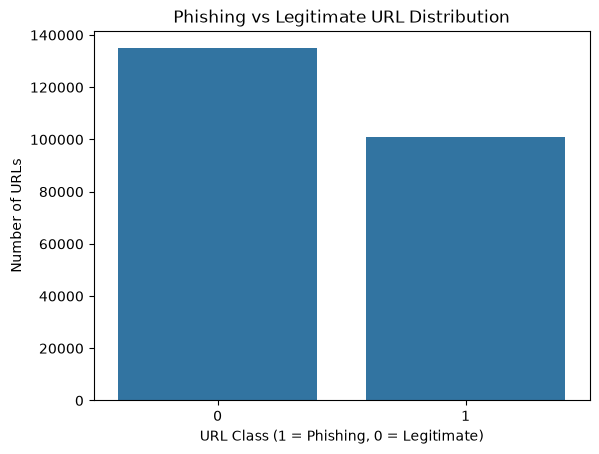

In [33]:
os.makedirs("graphs", exist_ok=True)

sns.countplot(x=y)

plt.title("Phishing vs Legitimate URL Distribution")
plt.xlabel("URL Class (1 = Phishing, 0 = Legitimate)")
plt.ylabel("Number of URLs")

plt.savefig(os.path.join("graphs", "url_distribution.png"), bbox_inches="tight")
plt.show()

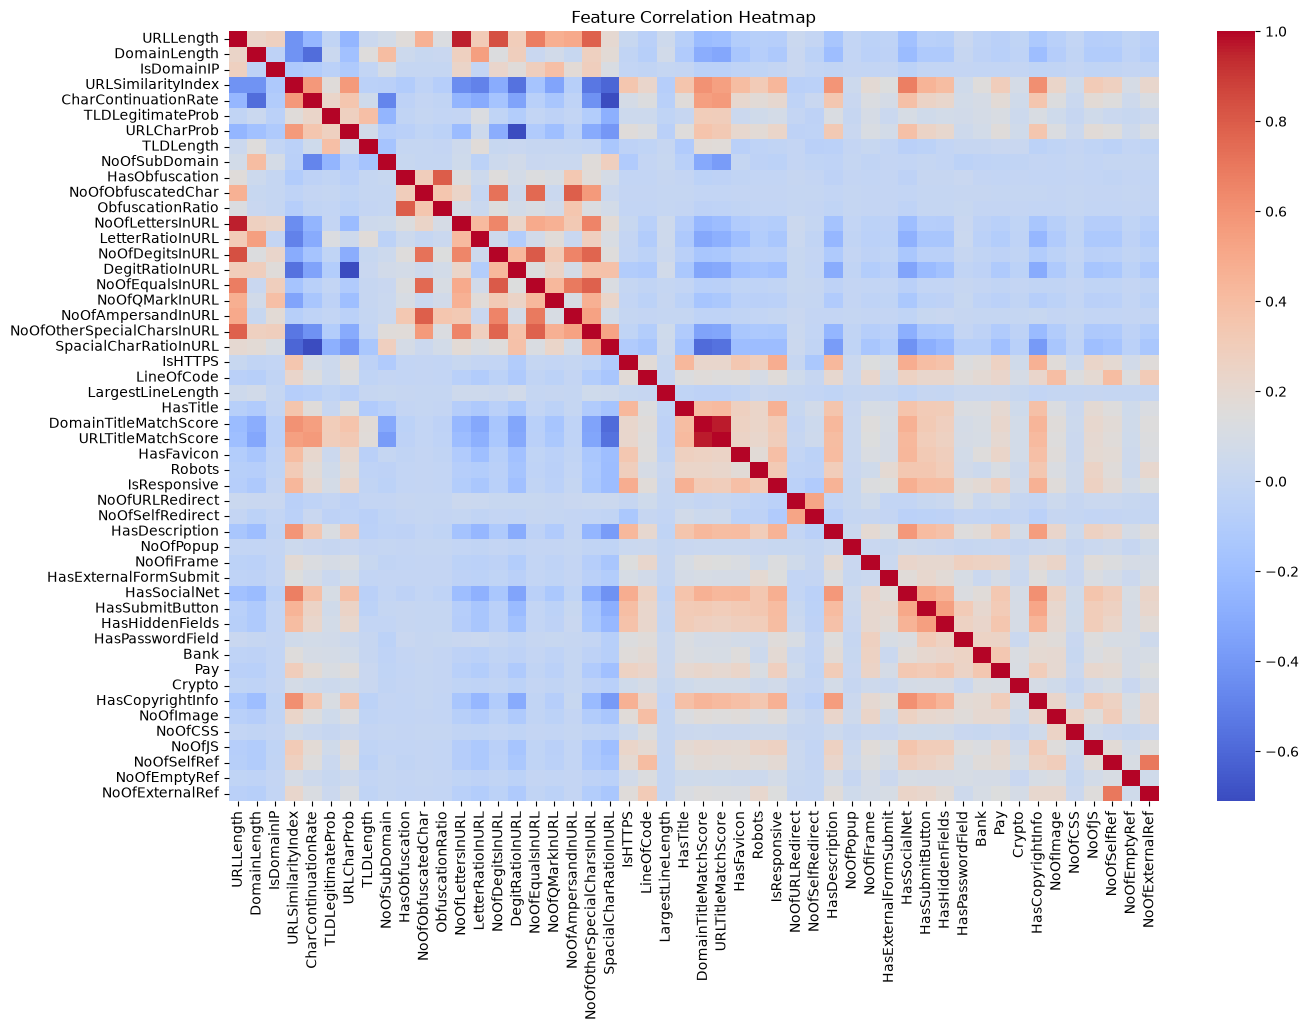

In [34]:
plt.figure(figsize=(15, 10))

sns.heatmap(
    X.corr(numeric_only=True),
    cmap='coolwarm',
    annot=False
)

plt.title("Feature Correlation Heatmap")
plt.savefig(os.path.join("graphs", "correlation_heatmap.png"), bbox_inches="tight")
plt.show()

In [35]:
import warnings
warnings.filterwarnings('ignore')

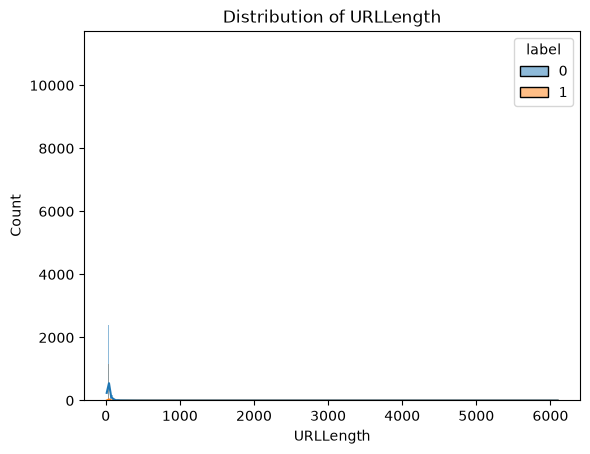

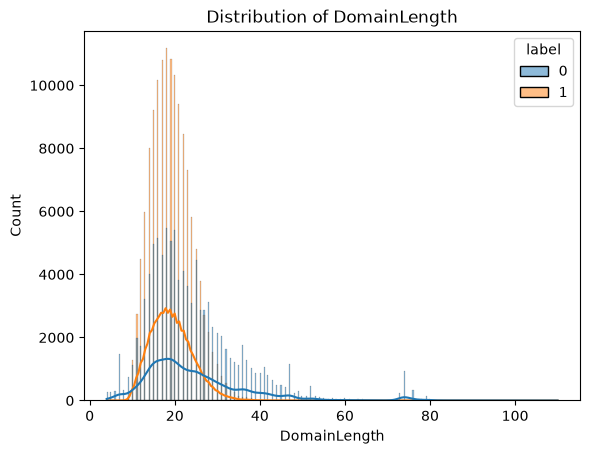

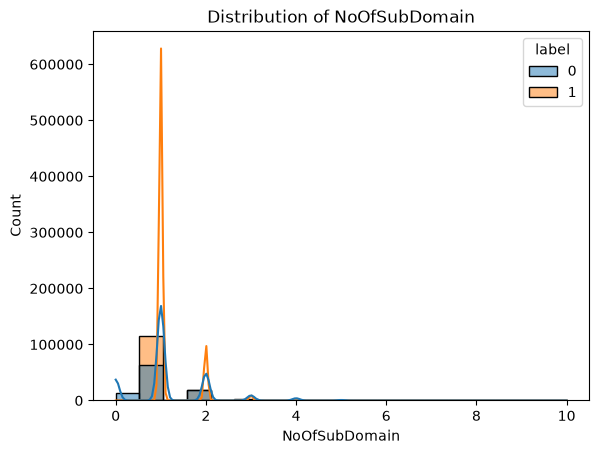

In [36]:
features = ['URLLength', 'DomainLength', 'NoOfSubDomain']

for col in features:
    if col in df.columns:
        plt.figure(figsize=(6, 4))
        sns.histplot(
            data=df,
            x=col,
            hue='label',
            kde=True
        )
        plt.title(f"Distribution of {col}")
        plt.savefig(os.path.join("graphs", f"distribution_{col}.png"), bbox_inches="tight")
        plt.show()

In [37]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

selector = SelectKBest(
    score_func=mutual_info_classif,
    k=20
)

X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

print("Before:", X_train.shape)
print("After:", X_train_selected.shape)

Before: (188636, 50)
After: (188636, 20)


In [38]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original:", X_train.shape)
print("PCA:", X_train_pca.shape)

Original: (188636, 50)
PCA: (188636, 37)


In [39]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', random_state=42)

svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)

In [40]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

In [41]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

models = {
    "SVM": svm_pred,
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred
}

for name, pred in models.items():

    print("\n", name)

    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred))
    print("Recall:", recall_score(y_test, pred))
    print("F1 Score:", f1_score(y_test, pred))

    print(classification_report(y_test, pred))


 SVM
Accuracy: 0.9998091562586144
Precision: 1.0
Recall: 0.9995527728085868
F1 Score: 0.9997763363900694
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     27035
           1       1.00      1.00      1.00     20124

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159


 Logistic Regression
Accuracy: 0.9998303611187684
Precision: 1.0
Recall: 0.9996024647187438
F1 Score: 0.9998011928429423
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     27035
           1       1.00      1.00      1.00     20124

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159


 Random Forest
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
              precision    recall  f1-score   s

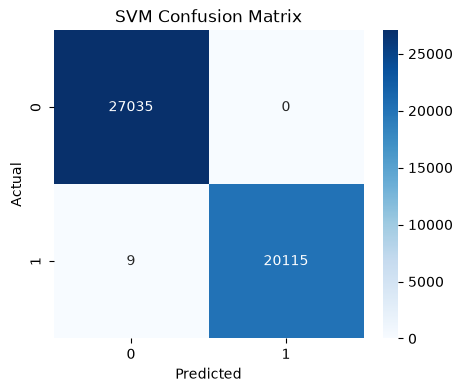

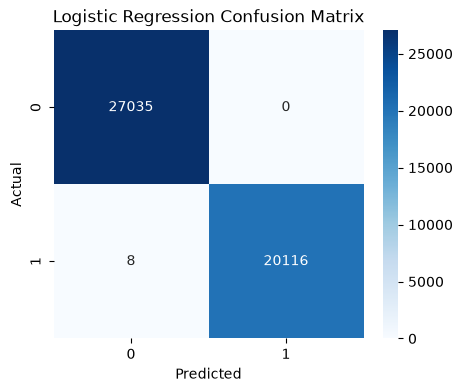

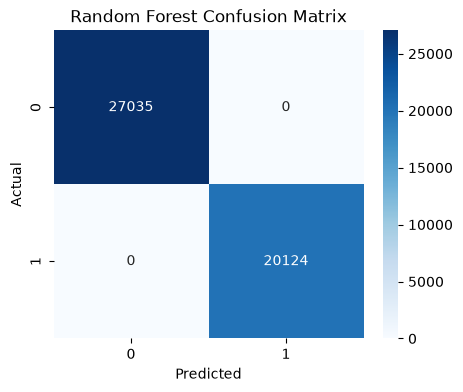

In [43]:
for name, pred in models.items():

    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    clean_name = name.lower().replace(" ", "_")
    plt.savefig(os.path.join("graphs", f"{clean_name}_confusion_matrix.png"), bbox_inches="tight")
    plt.show()

             Algorithm  Accuracy  Precision    Recall  F1 Score
0                  SVM  0.999809        1.0  0.999553  0.999776
1  Logistic Regression  0.999830        1.0  0.999602  0.999801
2        Random Forest  1.000000        1.0  1.000000  1.000000


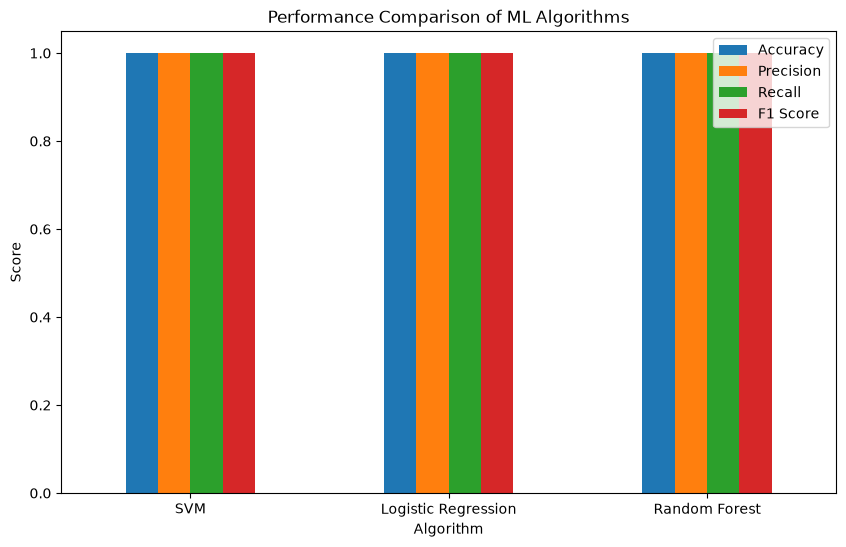

In [44]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)

results = []

for name, pred in models.items():

    results.append({
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1 Score': f1_score(y_test, pred)
    })

results_df = pd.DataFrame(results)

print(results_df)

results_df.set_index('Algorithm').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Performance Comparison of ML Algorithms")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.savefig(os.path.join("graphs", "model_comparison.png"), bbox_inches="tight")
plt.show()

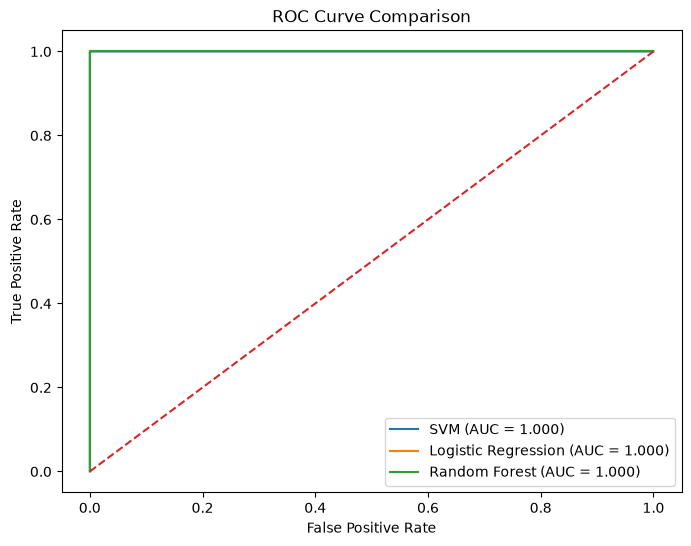

In [45]:
from sklearn.metrics import roc_curve, auc

models_probability = { 
    "SVM": svm.decision_function(X_test_scaled),
    "Logistic Regression": lr.predict_proba(X_test_scaled)[:, 1],
    "Random Forest": rf.predict_proba(X_test)[:, 1]
}

plt.figure(figsize=(8, 6))

for name, probability in models_probability.items():

    fpr, tpr, thresholds = roc_curve(y_test, probability)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {roc_auc:.3f})'
    )

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.savefig(os.path.join("graphs", "roc_curve_comparison.png"), bbox_inches="tight")
plt.show()

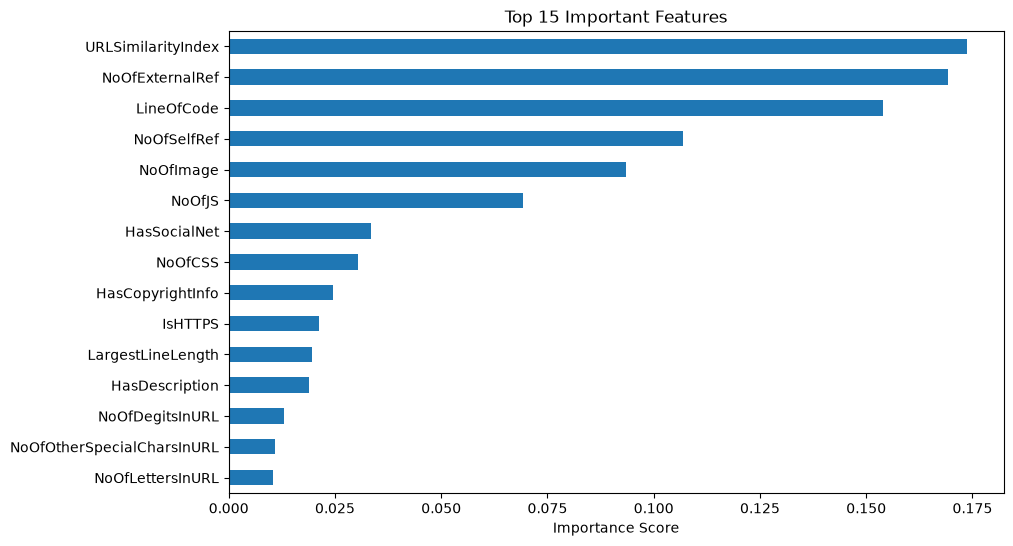

In [46]:
importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
)

importance = importance.sort_values(
    ascending=False
).head(15)

importance.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance Score")
plt.savefig(os.path.join("graphs", "top_15_features.png"), bbox_inches="tight")
plt.show()

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Original features
svm_original = SVC(kernel='rbf')

svm_original.fit(X_train_scaled, y_train)

pred_original = svm_original.predict(X_test_scaled)


# Selected features
svm_selected = SVC(kernel='rbf')

svm_selected.fit(
    X_train_selected,
    y_train
)

pred_selected = svm_selected.predict(
    X_test_selected
)


# PCA features
svm_pca = SVC(kernel='rbf')

svm_pca.fit(
    X_train_pca,
    y_train
)

pred_pca = svm_pca.predict(
    X_test_pca
)


# Compare accuracy
print("Original SVM:",
      accuracy_score(y_test, pred_original))

print("Feature Selected SVM:",
      accuracy_score(y_test, pred_selected))

print("PCA SVM:",
      accuracy_score(y_test, pred_pca))

In [ ]:
import joblib
import os

# Ensure models directory exists and save model
os.makedirs("models", exist_ok=True)
model_path = os.path.join("models", "phishing_detector.pkl")
joblib.dump(rf, model_path)

print(f"Model saved successfully to {model_path}!")